In [1]:
#@title **Importar bibliotecas** { vertical-output: true, form-width: "60%" }

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

1. Considere a quantidade de placa bacteriana antes e depois do tratamento.

a. Faça o boxplot dos dados antes e depois do tratamento

b. Construa o histograma para antes e depois.

c. A distribuição é normal?

d. Podemos afirmar que com IC=95% que há diferença na quantidade de placa bacteriana antes e depois?


In [ ]:
 # Criando a tabela usando pandas
dados = {
    "sujeito": range(1, 27),
    "antes": [2.18, 2.05, 1.05, 1.95, 0.28, 2.63, 1.5, 0.45, 0.7, 1.3, 1.25, 0.18, 3.3, 1.4, 0.9, 0.58, 2.5, 2.25, 1.53, 1.43, 3.48, 1.8, 1.5, 2.55, 1.3, 2.65],
    "depois": [0.43, 0.08, 0.18, 0.78, 0.03, 0.23, 0.2, 0.0, 0.05, 0.3, 0.33, 0.0, 0.9, 0.24, 0.15, 0.1, 0.33, 0.33, 0.53, 0.43, 0.65, 0.2, 0.25, 0.15, 0.05, 0.25]
}

tabela = pd.DataFrame(dados)
print("\nTabela de dados:")
print(tabela)


Tabela de dados:
    sujeito  antes  depois
0         1   2.18    0.43
1         2   2.05    0.08
2         3   1.05    0.18
3         4   1.95    0.78
4         5   0.28    0.03
5         6   2.63    0.23
6         7   1.50    0.20
7         8   0.45    0.00
8         9   0.70    0.05
9        10   1.30    0.30
10       11   1.25    0.33
11       12   0.18    0.00
12       13   3.30    0.90
13       14   1.40    0.24
14       15   0.90    0.15
15       16   0.58    0.10
16       17   2.50    0.33
17       18   2.25    0.33
18       19   1.53    0.53
19       20   1.43    0.43
20       21   3.48    0.65
21       22   1.80    0.20
22       23   1.50    0.25
23       24   2.55    0.15
24       25   1.30    0.05
25       26   2.65    0.25


In [ ]:
#Vamos analisar as pistas para saber se vale a pena testar o pressuposto de normalidade
# Estatísticas resumidas
print("Estatísticas resumidas para 'antes':\n", tabela['antes'].describe())
print("\nEstatísticas resumidas para 'depois':\n", tabela['depois'].describe())

Estatísticas resumidas para 'antes':
 count    26.000000
mean      1.641923
std       0.883154
min       0.180000
25%       1.100000
50%       1.500000
75%       2.232500
max       3.480000
Name: antes, dtype: float64

Estatísticas resumidas para 'depois':
 count    26.000000
mean      0.275769
std       0.232055
min       0.000000
25%       0.112500
50%       0.235000
75%       0.330000
max       0.900000
Name: depois, dtype: float64


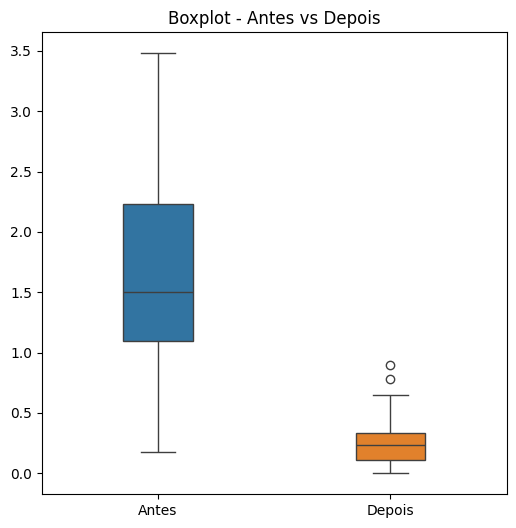

In [ ]:
#a. Faça o boxplot dos dados antes e depois do tratamento
# Boxplot combinado
plt.figure(figsize=(6, 6))
sns.boxplot(data=[tabela['antes'], tabela['depois']], width=0.3)
plt.xticks([0, 1], ['Antes', 'Depois'])
plt.title('Boxplot - Antes vs Depois')
plt.show()

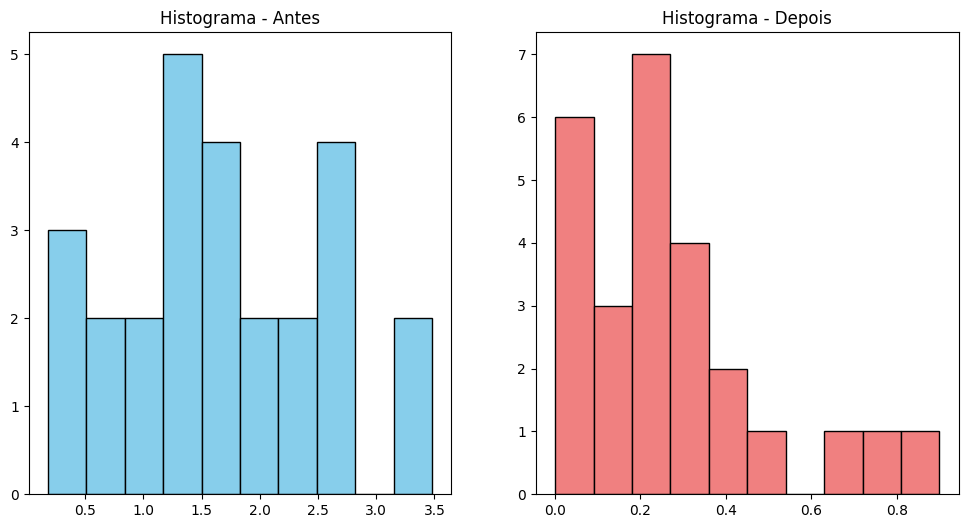

In [ ]:
#b. Construa o histograma para antes e depois.
# Histogramas
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.hist(tabela['antes'], bins=10, color='skyblue', edgecolor='black')
plt.title('Histograma - Antes')

plt.subplot(1, 2, 2)
plt.hist(tabela['depois'], bins=10, color='lightcoral', edgecolor='black')
plt.title('Histograma - Depois')

plt.show()

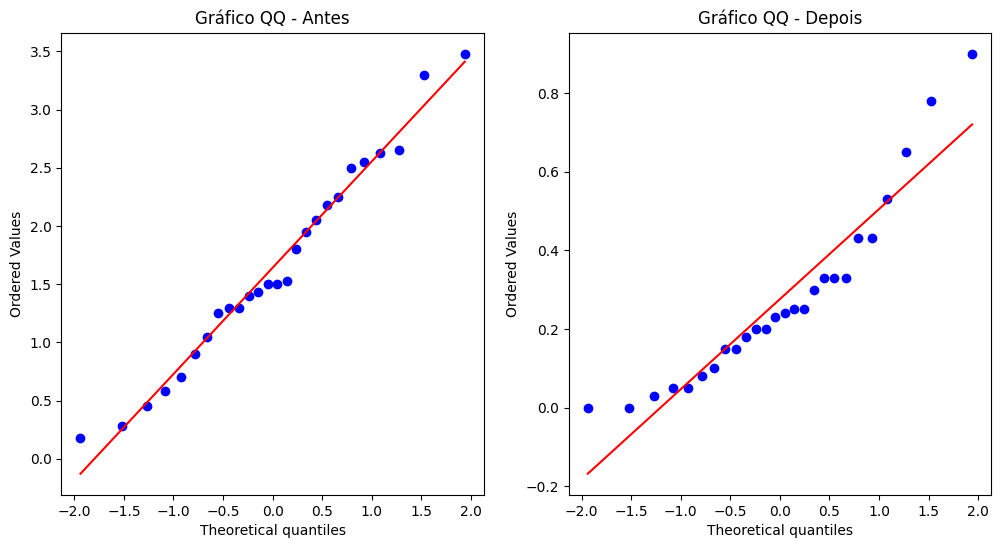

In [ ]:
#c. A distribuição é normal?
# QQ plots - Verificam visualmente a normalidade
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

stats.probplot(tabela['antes'], dist="norm", plot=ax[0])
ax[0].set_title('Gráfico QQ - Antes')

stats.probplot(tabela['depois'], dist="norm", plot=ax[1])
ax[1].set_title('Gráfico QQ - Depois')

plt.show()


In [ ]:
# Teste de normalidade Shapiro-Wilk
shapiro_antes = stats.shapiro(tabela['antes'])
shapiro_depois = stats.shapiro(tabela['depois'])

print("Teste Shapiro-Wilk - Antes: W =", shapiro_antes.statistic, ", p-valor =", shapiro_antes.pvalue)
print("Teste Shapiro-Wilk - Depois: W =", shapiro_depois.statistic, ", p-valor =", shapiro_depois.pvalue)

Teste Shapiro-Wilk - Antes: W = 0.9732339629841745 , p-valor = 0.7081454646794901
Teste Shapiro-Wilk - Depois: W = 0.8941305665247418 , p-valor = 0.01160478822871869


In [ ]:
#d. Podemos afirmar que com IC=95% que há diferença na quantidade de placa bacteriana antes e depois?
#Testes de normalidade: antes: é normal; depois: não resultou normal, mas o histograma e o qqplot ainda viabilizam o teste de médias
# Teste de igualdade de variâncias (Levene): Verifica se as variâncias de "antes" e "depois" são homogêneas.

#O teste de variância deve ser feito quando temos 2 grupos. Neste caso, temos apenas 1 grupo. Portanto, esse resultado não é determinante.

f_stat, f_pvalue = stats.levene(tabela['antes'], tabela['depois'])
print("\nTeste de Levene para variâncias: Estatística F =", f_stat, ", p-valor =", f_pvalue)


Teste de Levene para variâncias: Estatística F = 22.1807135500991 , p-valor = 2.0093055527348824e-05


In [ ]:


# Teste t pareado (pareado: comparando a mesma amostra - do tipo antes e depois)
t_stat, t_pvalue = stats.ttest_rel(tabela['antes'], tabela['depois'], axis=0, nan_policy='propagate', alternative='two-sided')
print("\nTeste t pareado: Estatística t =", t_stat, ", p-valor =", t_pvalue)

#Forma geral do teste t pareado ttest_rel(a, b, axis=0, nan_policy='propagate', alternative='two-sided', *, keepdims=False)
### Parâmetros:
#a, b** `array_like`  : Os arrays devem ter o mesmo formato (shape).
#axis** `int` ou `None`, padrão: `0`
#Se for um inteiro, é o eixo do input ao longo do qual a estatística será calculada. A estatística de cada fatia do eixo (por exemplo, uma linha) do input aparecerá em um elemento correspondente da saída.
#Se for `None`, o input será achatado (raveled) antes de calcular a estatística.
#nan_policy** `{‘propagate’, ‘omit’, ‘raise’}` : Define como lidar com valores NaN no input:
#propagate**: Se um NaN estiver presente na fatia do eixo (por exemplo, linha) ao longo da qual a estatística é calculada, a entrada correspondente na saída será NaN.
#omit**: Os NaNs serão omitidos durante o cálculo. Se não restar dados suficientes na fatia do eixo para realizar o cálculo, a entrada correspondente na saída será NaN.
#raise**: Se um NaN estiver presente, um **ValueError** será gerado.
#alternative** `{‘two-sided’, ‘less’, ‘greater’}`, opcional  : Define a **hipótese alternativa**. As seguintes opções estão disponíveis (o padrão é `'two-sided'`):
#‘two-sided’**: As médias das distribuições subjacentes às amostras são diferentes.
#‘less’**: A média da distribuição subjacente da primeira amostra é menor que a média da distribuição da segunda amostra.
#‘greater’**: A média da distribuição subjacente da primeira amostra é maior que a média da distribuição da segunda amostra.


Teste t pareado: Estatística t = 9.286437318436676 , p-valor = 1.397790052287765e-09


2. Em um experimento sobre a eficácia de um tratamento, nx = 125 pacientes foram designados para o tratamento novo  e ny = 175 para o tratamento  tradicional. Considerando que  x = 94 (75,2%) dos pacientes submetidos ao novo tratamento  apresentaram melhora   e y = 113 (64,6%) dos pacientes submetidos ao tratamento tradicional apresentaram melhoras. Em um nível de significância α = 0,05, o novo tratamento  produz taxas de sucesso mais altas do que o tratamento tradicional? Qual é o intervalo de confiança a 95% da diferença nas taxas de sucesso?




Estatística Z: 1.962
p-valor: 0.02486
Conclusão: Rejeita H0 - aceitamos a hipótese alternativa, ou seja, de fato a proporação de sucesso da amostra x é maior que da y, e que é estatisticamente significante


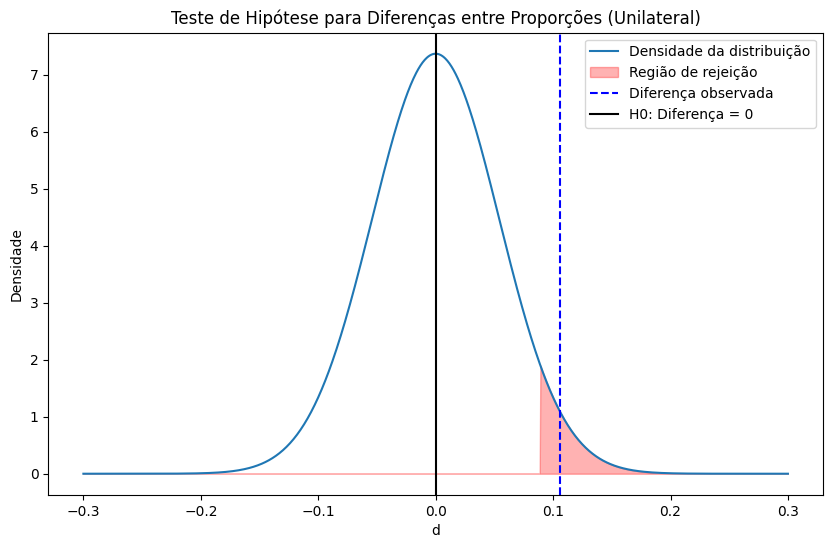

In [ ]:
!pip install statsmodels
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.stats.proportion import proportions_ztest


# Parâmetros do teste
x = np.array([94, 113])  # Sucessos
n = np.array([125, 175])  # Total de tentativas
alpha = 0.05  # Nível de significância

# Teste de proporções unilateral (alternative = "larger") alternative = [‘two-sided’, ‘smaller’, ‘larger’]
stat, p_value = proportions_ztest(count=x, nobs=n, alternative='larger')

# Resultados do teste
print(f"Estatística Z: {stat:.3f}")
print(f"p-valor: {p_value:.5f}")
print("Conclusão:", "Rejeita H0 - aceitamos a hipótese alternativa, ou seja, de fato a proporação de sucesso da amostra x é maior que da y, e que é estatisticamente significante")

#A solução do problema finalizou .. vamos apenas mostrar graficamente o que significa

# Cálculo do intervalo de rejeição
p_comb = (x[0] + x[1]) / (n[0] + n[1])  # Proporção combinada
se = np.sqrt(p_comb * (1 - p_comb) * (1 / n[0] + 1 / n[1]))  # Erro padrão
lrr = -np.inf  # Limite inferior da região de rejeição
urr = norm.ppf(1 - alpha, loc=0, scale=se)  # Limite superior

# Gráfico do teste de hipótese (unilateral)
d_values = np.linspace(-0.3, 0.3, 1000)
density = norm.pdf(d_values, loc=0, scale=se)
rejection_region = np.where(d_values > urr, density, 0)

plt.figure(figsize=(10, 6))
plt.plot(d_values, density, label="Densidade da distribuição")
plt.fill_between(d_values, rejection_region, color='red', alpha=0.3, label="Região de rejeição")
plt.axvline(x=(x[0] / n[0]) - (x[1] / n[1]), color='blue', linestyle='--', label="Diferença observada")
plt.axvline(x=0, color='black', linestyle='-', label="H0: Diferença = 0")
plt.title("Teste de Hipótese para Diferenças entre Proporções (Unilateral)")
plt.xlabel("d")
plt.ylabel("Densidade")
plt.legend()
plt.show()



Estudos anteriores mostraram quatro respostas possíveis a uma terapia com frequência: n1 = 0,50, n2 = 0,25, n3 = 0,10 e n4 = 0,15. Uma amostra aleatória de n = 200 produz n1 = 120, n2 = 60, n3 = 10 e n4=10. Em um nível de significância α = 0,05, a amostra aleatória confirma as frequências esperadas?


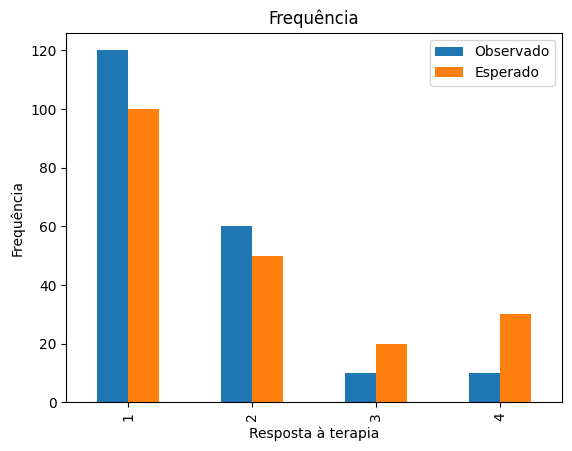

Chi-square Statistic: 24.333333333333336
P-value: 2.12805691984048e-05


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Frequências observadas
observed = np.array([120, 60, 10, 10])
n = 200  # Tamanho total da amostra

# Frequências esperadas
expected_proportions = np.array([0.50, 0.25, 0.10, 0.15])
expected = expected_proportions * n

# Nível de significância
alpha = 0.05

# Criar dataframe
df = pd.DataFrame({
    "Resposta": [1, 2, 3, 4],
    "Observado": observed,
    "Esperado": expected
})

# Gráfico
fig, ax = plt.subplots()
df.plot(x="Resposta", kind="bar", stacked=False, ax=ax)
plt.title("Frequência")
plt.xlabel("Resposta à terapia")
plt.ylabel("Frequência")
plt.legend(["Observado", "Esperado"])
plt.show()

# Teste de Chi-square
chi2_stat, p_value = stats.chisquare(f_obs=observed, f_exp=expected)

# Resultados
print(f"Chi-square Statistic: {chi2_stat}")
print(f"P-value: {p_value}")


**Exercícios**

1. Fazer os exercícios que estão no pdf em python